# Sprint 2: Exploratory Data Analysis (EDA)
## Customer Churn Prediction Project

This interactive notebook executes the exploratory data analysis workflow following the AIAP Foundation Companion guidelines and feedback recommendations. It includes:
1. **Preliminary Data Inspection & Missingness Audit** (raw state prior to cleaning)
2. **Target Class Imbalance Profiling** (counts and percentages)
3. **Univariate Analysis** (numerical histograms with KDE and categorical count plots)
4. **Bivariate Subgroup Analysis & Non-Parametric Hypothesis Testing** (Mann-Whitney U and Chi-Square tests)
5. **Domain Feature Interaction Engineering** (`spend_per_visit`, `complaint_dissatisfaction`)
6. **Multicollinearity & Correlation Analysis** (Pearson linear and Spearman rank matrices)

In [24]:
# Import required libraries and define ANSI terminal color constants
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency

# User defined ANSI color constants for terminal print output
RED_BOLD = "\033[1;31m"
GREEN_BOLD = "\033[1;32m"
CLEAR = "\033[0m"

# Set global plotting aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 10})

print(f"{GREEN_BOLD}[INFO] Environment and styling initialized successfully.{CLEAR}")

[INFO] Environment and styling initialized successfully.


## 1. Preliminary Data Exploration & Quality Audit
We inspect the raw dataset structure, row counts, data types, missingness distributions, and duplicate records prior to applying any data cleaning or imputation transformations.

In [25]:
# Load raw dataset
data_path = './data/synthetic_data_204.csv'
df = pd.read_csv(data_path)

print(f"{GREEN_BOLD}[INFO] Raw Dataset Shape: {df.shape}{CLEAR}")
print(f"{GREEN_BOLD}[INFO] Schema & Data Types:{CLEAR}")
df.info()

print(f"\n{RED_BOLD}[FINDING] Missing Values Audit (Before Cleaning):\n{df.isnull().sum()}{CLEAR}")
print(f"\n{RED_BOLD}[FINDING] Duplicate Rows Count: {df.duplicated().sum()}{CLEAR}")

print(f"\n{GREEN_BOLD}[INFO] Transposed Raw Summary Statistics:{CLEAR}")
df.describe(include='all').T

[INFO] Raw Dataset Shape: (1000, 7)
[INFO] Schema & Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   monthly_spend                     1000 non-null   float64
 1   number_of_store_visits_per_month  1000 non-null   float64
 2   customer_satisfaction_score       1000 non-null   float64
 3   number_of_complaints              1000 non-null   float64
 4   membership_tier                   1000 non-null   str    
 5   discount_usage_rate               1000 non-null   float64
 6   customer_churn                    1000 non-null   str    
dtypes: float64(5), str(2)
memory usage: 54.8 KB

[FINDING] Missing Values Audit (Before Cleaning):
monthly_spend                       0
number_of_store_visits_per_month    0
customer_satisfaction_score         0
number_of_complaints                0
membership_tier        

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
monthly_spend,1000.0,NaN,NaN,NaN,61.98522,33.48285,9.98,39.4125,54.645,76.0375,301.81
number_of_store_visits_per_month,1000.0,NaN,NaN,NaN,14.931411,8.788976,0.0345,7.135,14.665,22.33,30.0
customer_satisfaction_score,1000.0,NaN,NaN,NaN,0.769119,0.15339,0.179,0.6755,0.796,0.88925,0.995
number_of_complaints,1000.0,NaN,NaN,NaN,4.888184,2.869299,0.0107,2.38,4.87,7.4025,9.95
membership_tier,1000,3,Basic,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discount_usage_rate,1000.0,NaN,NaN,NaN,0.278599,0.15764,0.00277,0.154,0.2615,0.37275,0.824
customer_churn,1000,2,Retained,850,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Target Variable & Class Imbalance Analysis
Quantifying target variable (`customer_churn`) proportions to evaluate class imbalance severity and inform metric selection and cost-sensitive model penalties.

[FINDING] Target Class Counts:
customer_churn
Retained    850
Churned     150
Name: count, dtype: int64
[FINDING] Target Class Percentages (%):
customer_churn
Retained    85.0
Churned     15.0
Name: proportion, dtype: float64


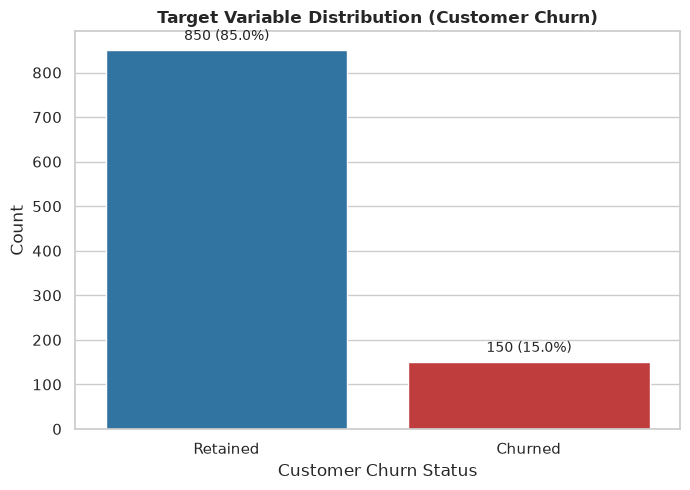

In [26]:
# Calculate raw target counts and percentages
churn_counts = df['customer_churn'].value_counts()
churn_props = df['customer_churn'].value_counts(normalize=True) * 100

print(f"{RED_BOLD}[FINDING] Target Class Counts:\n{churn_counts}{CLEAR}")
print(f"{RED_BOLD}[FINDING] Target Class Percentages (%):\n{churn_props}{CLEAR}")

# Construct binary target variable for correlation and subgroup calculations
df['churn_binary'] = (df['customer_churn'] == 'Churned').astype(int)

# Visual Plot of Target Class Distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x='customer_churn', palette=['#1f77b4', '#d62728'], ax=ax, hue='customer_churn')
ax.set_title("Target Variable Distribution (Customer Churn)", fontsize=12, fontweight='bold')
ax.set_xlabel("Customer Churn Status")
ax.set_ylabel("Count")

for p in ax.patches:
    h = p.get_height()
    pct = (h / len(df)) * 100
    ax.annotate(f"{int(h)} ({pct:.1f}%)", (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Univariate Distributions Analysis
Plotting continuous feature distributions using histograms with Kernel Density Estimation (KDE) overlays and analyzing categorical membership distributions.

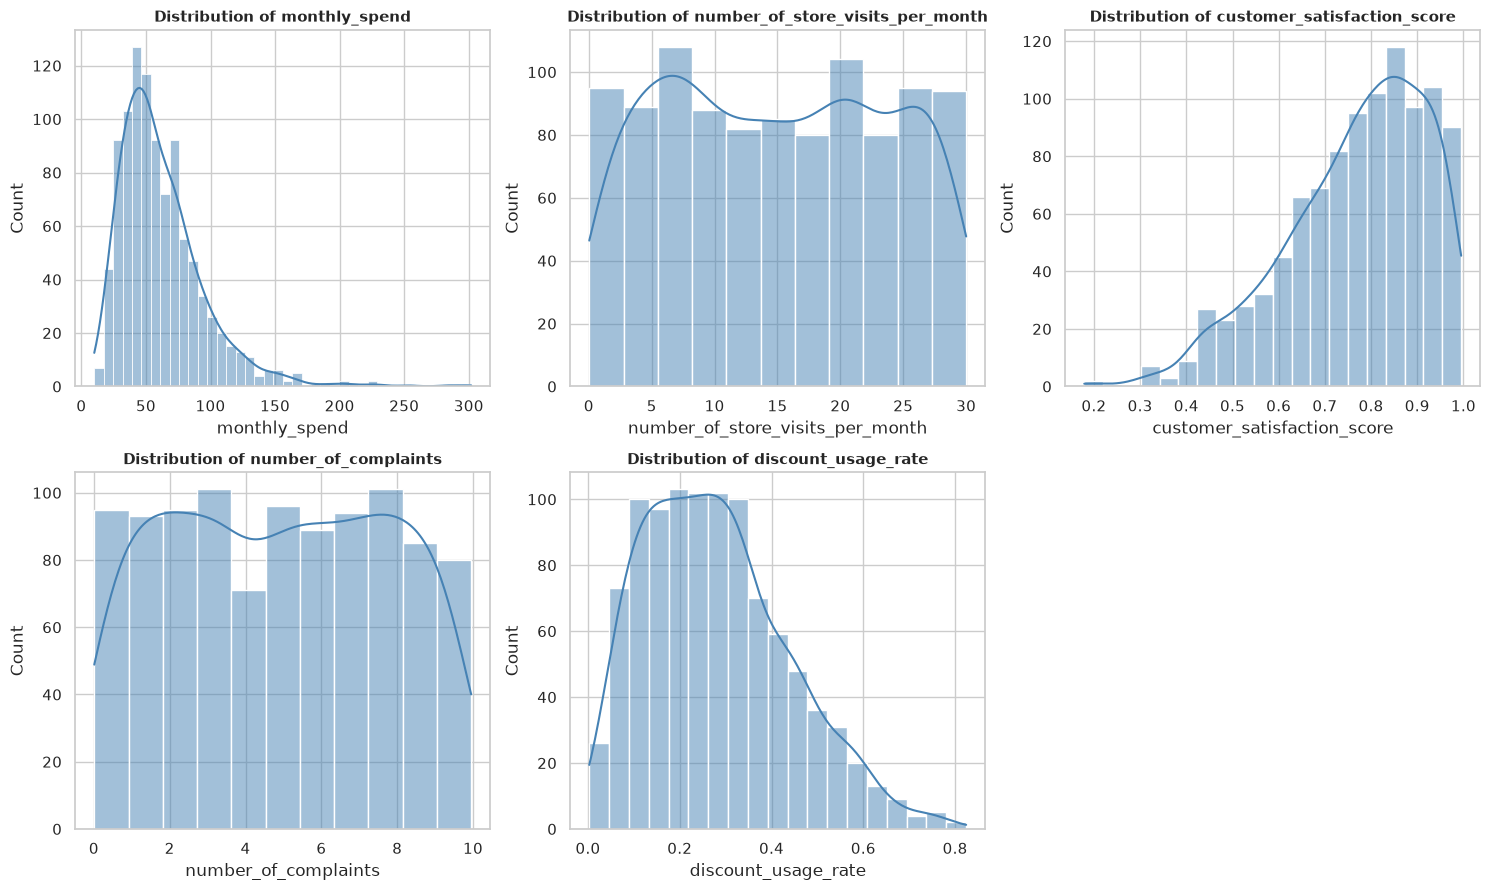

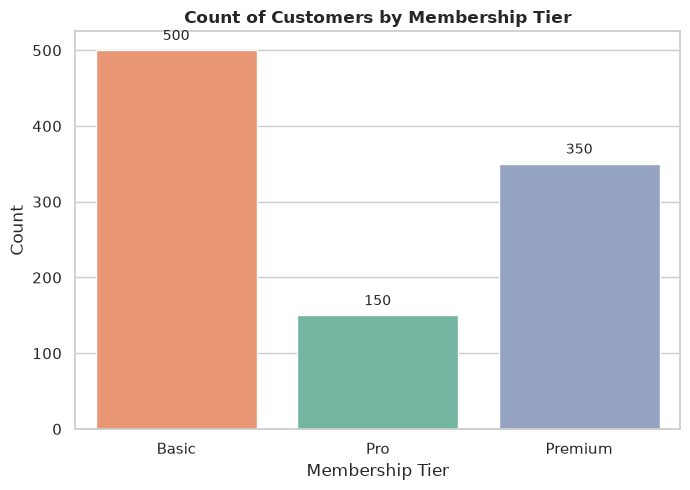

In [27]:
num_cols = ['monthly_spend', 'number_of_store_visits_per_month', 'customer_satisfaction_score', 'number_of_complaints', 'discount_usage_rate']

# Numerical Distributions Histograms + KDE
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"Distribution of {col}", fontsize=11, fontweight='bold')

axes[5].axis('off')
plt.tight_layout()
plt.show()

# Categorical Distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x='membership_tier', order=['Basic', 'Pro', 'Premium'], palette='Set2', ax=ax, hue='membership_tier')
ax.set_title("Count of Customers by Membership Tier", fontsize=12, fontweight='bold')
ax.set_xlabel("Membership Tier")
ax.set_ylabel("Count")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}", (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Bivariate Subgroup Analysis & Feature Interactions
Analyzing subgroup churn rates across `membership_tier`, evaluating continuous predictors against target status via boxplots and scatter plots, engineering domain interaction features, and conducting non-parametric statistical hypothesis tests.

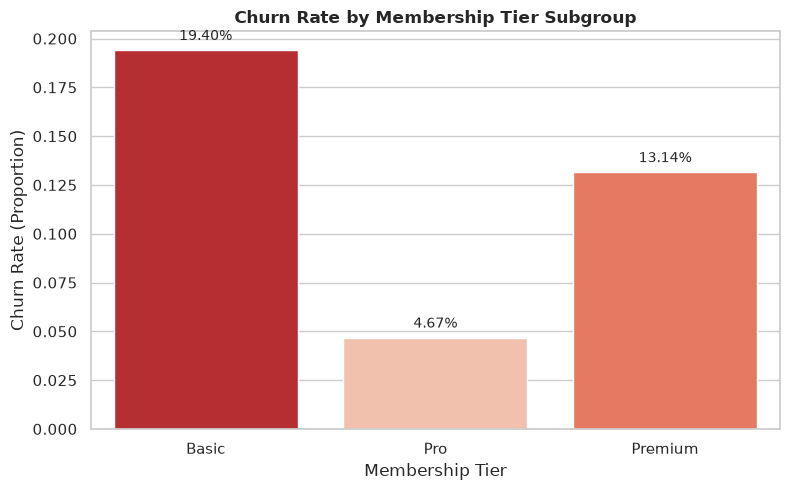

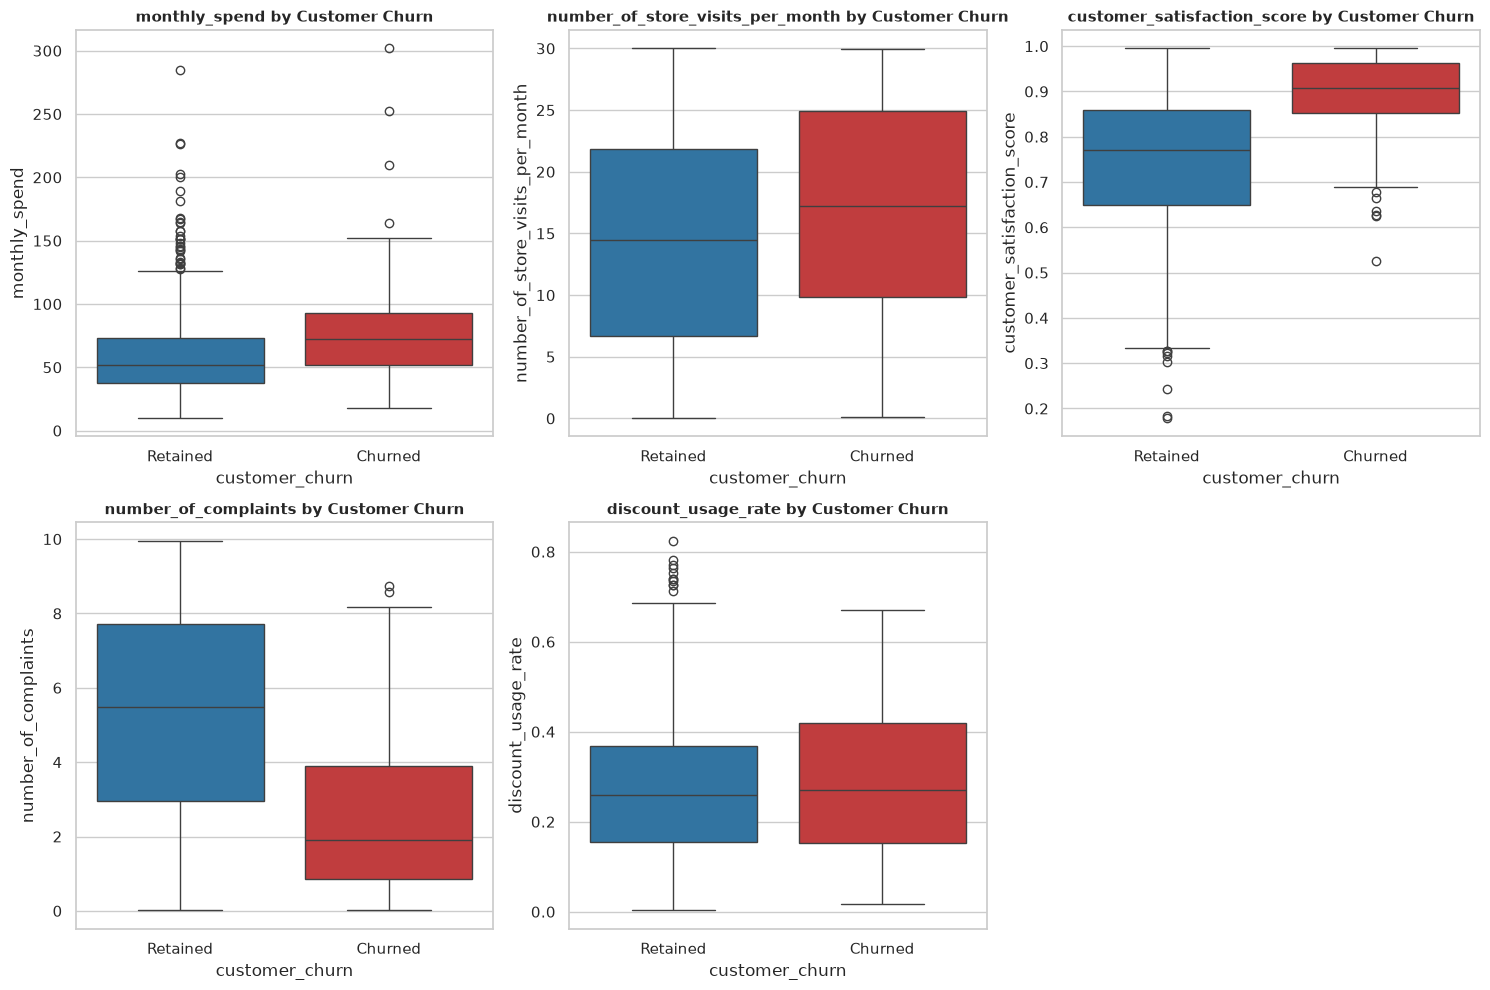

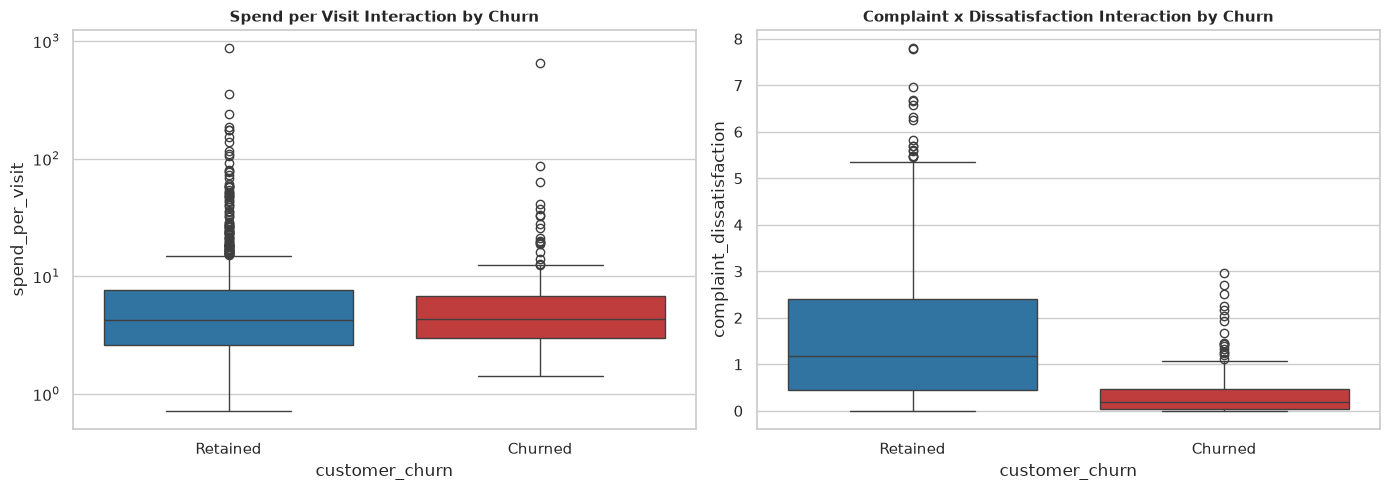

[INFO] --- STATISTICAL HYPOTHESIS TESTING RESULTS ---
[FINDING] Mann-Whitney U test for monthly_spend                   : Stat=41395.00, p-val=7.1501e-12 (Statistically Significant)
[FINDING] Mann-Whitney U test for number_of_store_visits_per_month: Stat=53630.00, p-val=1.9159e-03 (Statistically Significant)
[FINDING] Mann-Whitney U test for customer_satisfaction_score     : Stat=26072.00, p-val=7.1105e-31 (Statistically Significant)
[FINDING] Mann-Whitney U test for number_of_complaints            : Stat=96148.00, p-val=2.9569e-23 (Statistically Significant)
[FINDING] Mann-Whitney U test for discount_usage_rate             : Stat=62722.00, p-val=7.5271e-01 (Not Significant)
[FINDING] Mann-Whitney U test for spend_per_visit                 : Stat=60260.00, p-val=2.8462e-01 (Not Significant)
[FINDING] Mann-Whitney U test for complaint_dissatisfaction       : Stat=102076.00, p-val=6.9088e-32 (Statistically Significant)
[FINDING] Chi-Square test for membership_tier vs target  : Chi2=21.10

In [28]:
# Subgroup Churn Rate by Membership Tier
fig, ax = plt.subplots(figsize=(8, 5))
tier_churn = df.groupby('membership_tier')['churn_binary'].mean().reset_index()
sns.barplot(data=tier_churn, x='membership_tier', y='churn_binary', order=['Basic', 'Pro', 'Premium'], palette='Reds_r', ax=ax, hue='membership_tier', legend=False)
ax.set_title("Churn Rate by Membership Tier Subgroup", fontsize=12, fontweight='bold')
ax.set_xlabel("Membership Tier")
ax.set_ylabel("Churn Rate (Proportion)")

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2%}", (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# Bivariate Continuous Boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='customer_churn', y=col, palette=['#1f77b4', '#d62728'], ax=axes[i], hue='customer_churn', legend=False)
    axes[i].set_title(f"{col} by Customer Churn", fontsize=11, fontweight='bold')

axes[5].axis('off')
plt.tight_layout()
plt.show()

# Engineer Domain Interaction Features
df['spend_per_visit'] = df['monthly_spend'] / (df['number_of_store_visits_per_month'] + 1e-5)
df['complaint_dissatisfaction'] = df['number_of_complaints'] * (1.0 - df['customer_satisfaction_score'])

# Plot Interaction Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='customer_churn', y='spend_per_visit', palette=['#1f77b4', '#d62728'], ax=axes[0], hue='customer_churn', legend=False)
axes[0].set_title("Spend per Visit Interaction by Churn", fontsize=11, fontweight='bold')
axes[0].set_yscale('log')

sns.boxplot(data=df, x='customer_churn', y='complaint_dissatisfaction', palette=['#1f77b4', '#d62728'], ax=axes[1], hue='customer_churn', legend=False)
axes[1].set_title("Complaint x Dissatisfaction Interaction by Churn", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Non-Parametric Hypothesis Testing (Mann-Whitney U & Chi-Square)
print(f"{GREEN_BOLD}[INFO] --- STATISTICAL HYPOTHESIS TESTING RESULTS ---{CLEAR}")
retained = df[df['customer_churn'] == 'Retained']
churned = df[df['customer_churn'] == 'Churned']
all_num_cols = num_cols + ['spend_per_visit', 'complaint_dissatisfaction']

for col in all_num_cols:
    stat, p_val = mannwhitneyu(retained[col], churned[col], alternative='two-sided')
    status = "Statistically Significant" if p_val < 0.05 else "Not Significant"
    print(f"{RED_BOLD}[FINDING] Mann-Whitney U test for {col:32s}: Stat={stat:.2f}, p-val={p_val:.4e} ({status}){CLEAR}")

contingency = pd.crosstab(df['membership_tier'], df['customer_churn'])
chi2, p_val, dof, ex = chi2_contingency(contingency)
status = "Statistically Significant" if p_val < 0.05 else "Not Significant"
print(f"{RED_BOLD}[FINDING] Chi-Square test for membership_tier vs target  : Chi2={chi2:.2f}, p-val={p_val:.4e} ({status}){CLEAR}")

## 5. Correlation & Multicollinearity Analysis
Computing and visualizing Pearson (linear) and Spearman Rank (monotonic) correlation heatmaps to assess feature redundancy and multicollinearity risks.

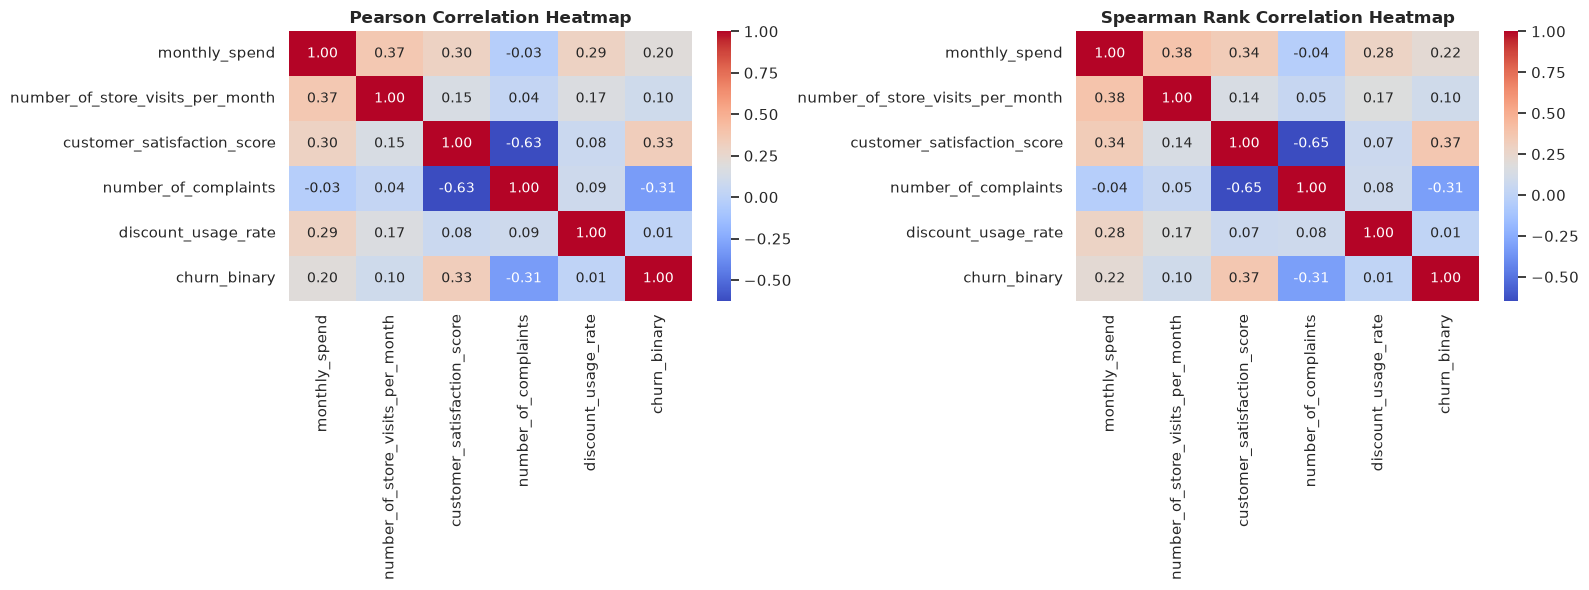

In [29]:
numeric_df = df[num_cols + ['churn_binary']]
pearson_corr = numeric_df.corr(method='pearson')
spearman_corr = numeric_df.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=axes[0])
axes[0].set_title("Pearson Correlation Heatmap", fontsize=12, fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1])
axes[1].set_title("Spearman Rank Correlation Heatmap", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()